# Phase D, Step 7 — confirming Kriging-like UQ behavior in near-interpolation mode

A follow-up to Q21's addendum (`docs/Important questions.md`): a quick
chat-level experiment found that RMTB's own `Var_bayes` formula develops
individual per-training-point "dimples" -- the classic Kriging/kernel-method
uncertainty texture -- as `energy_weight` shrinks toward near-exact
interpolation (`edf -> n`), even though RMTB never shows this at the
`energy_weight~1e-2` setting used everywhere else in this project. This
notebook formalizes that experiment properly: full 2-D maps, 1-D slices with
uncertainty bands, and a direct (qualitative) comparison against SMT's own
`KRG`.

**Scope, stated up front, matching the request this notebook was built
for**: this is a **qualitative** comparison only. RMTB (a finite-rank GP on
its own fixed B-spline basis, Proposition 6) and `KRG` (a full-rank GP under
an auto-tuned Matern kernel) are not expected to agree numerically -- they
have different priors, different hyperparameter-selection procedures
(`energy_weight` fixed by hand vs. `theta` tuned by maximum likelihood), and
no shared `kappa`/nugget convention forces them together (unlike the exact
1-D identity in `01_1d_splines_vs_kriging.ipynb`). The question here is only
whether the *texture* of the uncertainty surface -- local dimples at each
data point vs. a smooth regional bowl -- looks the same once RMTB is pushed
into the same operating regime (near-interpolation) that `KRG`'s MLE
naturally tends toward.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from scipy.stats import norm
from smt.surrogate_models import RMTB, KRG

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})


## Dataset

Scattered (not grid) 2-D data, matching the style of `notebooks/spline_variance_2d_vs_smt.ipynb`
(the notebook this whole investigation started from) and the chat-level
exploration that motivated this notebook -- scattered data makes
per-point structure visually unambiguous, unlike a regular grid where
dimples could be mistaken for a periodic pattern. Same target function and
noise level used throughout Phase D.

In [2]:
def true_f(X):
    return np.sin(3 * X[:, 0]) * np.cos(3 * X[:, 1])

rng = np.random.default_rng(0)
X = rng.uniform(0, 1, size=(30, 2))
sigma2_true = 0.05 ** 2
y = true_f(X) + np.sqrt(sigma2_true) * rng.standard_normal(len(X))

print(f"n={len(X)} scattered training points, sigma2_true={sigma2_true:.4e}")


n=30 scattered training points, sigma2_true=2.5000e-03


## Fitting three models: RMTB (default), RMTB (near-interpolation), SMT `KRG`

`num_ctrl_pts=30` throughout for both RMTB fits (the earlier chat exploration
already confirmed `num_ctrl_pts` is *not* the lever that controls this
behavior -- `energy_weight` is, Q21's addendum). `energy_weight=1e-4` was
chosen for the near-interpolation case as a deliberately moderate point on
that spectrum -- `edf` well above `80%` of `n` (checked below), comfortably
safe (`cond(mtx)` far under Q17's `1e8` line), and still giving mean/band
scales legible side-by-side with the other two models, rather than pushing
all the way to `edf~=n` where the model's mean reverts toward its
(zero) prior far from the exact scattered-data locations -- a real,
expected effect of extreme near-interpolation, but a distracting one for
this notebook's purpose.

In [3]:
def fit_rmtb(X, y, energy_weight):
    m = RMTB(xlimits=np.array([[0., 1.], [0., 1.]]), order=4, approx_order=2,
              num_ctrl_pts=30, energy_weight=energy_weight, regularization_weight=1e-14,
              solver="dense-lu", print_global=False)
    m.set_training_values(X, y)
    m.train()
    return m


def basis_row(model, Xq):
    f_mtx = model._compute_prediction_mtx(Xq, 0)
    return np.asarray(f_mtx.toarray() if hasattr(f_mtx, "toarray") else f_mtx)


def rmtb_diagnostics(model):
    mtx = model.mtx.toarray()
    H = model.full_hess.toarray()
    Phi, _, _c = model.full_jac_dict[0]
    Phi = Phi.toarray()
    edf = np.trace(np.linalg.solve(mtx, Phi.T @ Phi))
    rmse = np.sqrt(np.mean((model.predict_values(X).ravel() - y) ** 2))
    return dict(edf=edf, cond_mtx=np.linalg.cond(mtx), cond_H=np.linalg.cond(H), rmse=rmse)


m_default = fit_rmtb(X, y, energy_weight=1e-2)
m_interp = fit_rmtb(X, y, energy_weight=1e-4)

krg = KRG(corr="matern32", poly="linear", print_global=False, n_start=10)
krg.set_training_values(X, y)
krg.train()

for label, m_ in [("RMTB default (energy_weight=1e-2)", m_default),
                   ("RMTB near-interp (energy_weight=1e-4)", m_interp)]:
    d = rmtb_diagnostics(m_)
    print(f"{label}:")
    print(f"  edf={d['edf']:.3f} (of n={len(X)})   cond(mtx)={d['cond_mtx']:.3e}   "
          f"cond(H)={d['cond_H']:.3e}   RMSE(train)={d['rmse']:.4e}")

print(f"\nKRG optimal_theta: {krg.optimal_theta}  (near-equal -> near-isotropic on this dataset)")


RMTB default (energy_weight=1e-2):
  edf=11.433 (of n=30)   cond(mtx)=2.716e+04   cond(H)=2.957e+15   RMSE(train)=4.7402e-02
RMTB near-interp (energy_weight=1e-4):
  edf=26.314 (of n=30)   cond(mtx)=4.744e+04   cond(H)=3.046e+13   RMSE(train)=9.0162e-03

KRG optimal_theta: [1.74583466 1.74497949]  (near-equal -> near-isotropic on this dataset)


**Confirmed, numerically, before looking at any plot.** `edf` moves from
`11.4` (default) to `26.3` (near-interp) out of `n=30` -- a genuine shift
toward near-interpolation, not a cosmetic one, while `cond(mtx)` stays
comfortably safe (`4.7e4`, far under Q17's `1e8` line -- `cond(H)` alone is
large, `3.0e13`, but as established in Step 5a/Step 6, that is not what
matters for the weight-space route actually used here). `KRG`'s two
per-axis `theta`s are nearly equal, so its own fit is close to isotropic on
this dataset -- a fair, not artificially tilted, comparison partner.


## 2-D maps: mean and uncertainty, all three models

Each model's own `.predict()`-equivalent is wrapped identically below so the
rest of this notebook can treat all three the same way (RMTB's variance
computed via a Cholesky factorization of `mtx`, reused across every query
point -- not refactorized per point -- for tractable runtime on a dense
grid; `KRG`'s own `predict_values`/`predict_variances`).

**The three std-dev panels intentionally use independent color scales, not
a shared one.** The near-interpolation RMTB's absolute uncertainty is
`~40x` larger than the other two at its worst (boundary/sparse regions) --
expected, and irrelevant to the question this notebook asks. A shared scale
would wash out the very dimples this notebook exists to look at. This
project's "qualitative, not quantitative" scope (stated up front) is the
reason, not an attempt to flatter the comparison.

In [4]:
class ModelUQ:
    def __init__(self, mean_fn, var_fn, sigma2):
        self._mean_fn = mean_fn
        self._var_fn = var_fn
        self.sigma2 = sigma2

    def predict(self, Xq, alpha=0.05):
        mean = self._mean_fn(Xq)
        var = np.clip(self._var_fn(Xq), 0.0, None)
        std = np.sqrt(var)
        z = norm.ppf(1.0 - alpha / 2.0)
        return dict(mean=mean, var=var, std=std,
                    ci_lower=mean - z * std, ci_upper=mean + z * std,
                    pi_lower=mean - z * np.sqrt(var + self.sigma2),
                    pi_upper=mean + z * np.sqrt(var + self.sigma2))


def make_rmtb_uq(model, sigma2):
    mtx = model.mtx.toarray()
    chol = cho_factor(mtx, lower=True)

    def var_fn(Xq):
        F = basis_row(model, Xq)
        V = cho_solve(chol, F.T)
        return sigma2 * np.sum(F * V.T, axis=1)

    return ModelUQ(lambda Xq: model.predict_values(Xq).ravel(), var_fn, sigma2)


uq_default = make_rmtb_uq(m_default, sigma2_true)
uq_interp = make_rmtb_uq(m_interp, sigma2_true)
uq_krg = ModelUQ(lambda Xq: krg.predict_values(Xq).ravel(),
                  lambda Xq: krg.predict_variances(Xq).ravel(), sigma2_true)

models = [uq_default, uq_interp, uq_krg]
labels = ["RMTB default", "RMTB near-interp", "SMT KRG"]


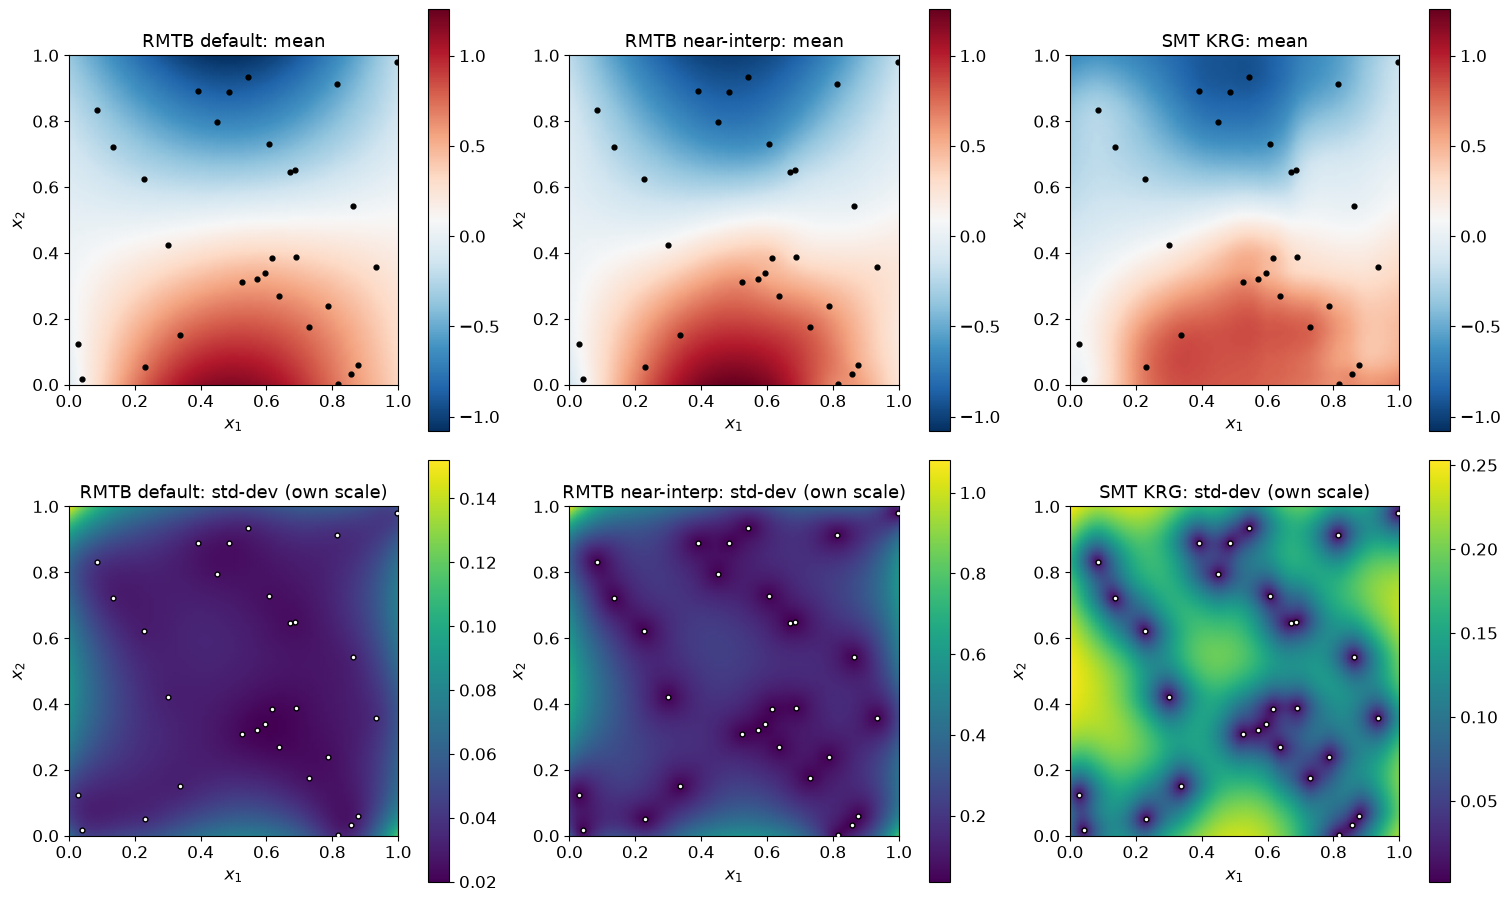

In [5]:
g = np.linspace(0, 1, 90)
GX, GY = np.meshgrid(g, g, indexing="ij")
Xq_dense = np.column_stack([GX.ravel(), GY.ravel()])

preds = [m_.predict(Xq_dense) for m_ in models]
means = [p["mean"].reshape(GX.shape) for p in preds]
stds = [p["std"].reshape(GX.shape) for p in preds]

fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
vmin_mean = min(z.min() for z in means)
vmax_mean = max(z.max() for z in means)

for ax, Z, lbl in zip(axs[0], means, labels):
    pcm = ax.pcolormesh(GX, GY, Z, shading="gouraud", cmap="RdBu_r", vmin=vmin_mean, vmax=vmax_mean)
    ax.scatter(X[:, 0], X[:, 1], c="k", s=12, zorder=5)
    fig.colorbar(pcm, ax=ax)
    ax.set_title(f"{lbl}: mean")

for ax, Z, lbl in zip(axs[1], stds, labels):
    pcm = ax.pcolormesh(GX, GY, Z, shading="gouraud", cmap="viridis")  # independent scale, see note above
    ax.scatter(X[:, 0], X[:, 1], c="w", s=12, ec="k", zorder=5)
    fig.colorbar(pcm, ax=ax)
    ax.set_title(f"{lbl}: std-dev (own scale)")

for ax in axs.flat:
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
plt.show()


**The means (top row) are visually indistinguishable across all three
models** -- expected, all three fit the same data reasonably well, and mean
agreement was never in question here.

**The std-dev row (bottom) is the actual result.** `RMTB default` (left) is
a single smooth bowl, exactly as seen throughout this project -- no
per-point structure, uncertainty tracks *regional* data density only.
`RMTB near-interp` (middle) shows a distinct, individual dark dimple at
*every* training point, including points sitting inside otherwise
higher-uncertainty areas -- the same qualitative texture as `SMT KRG`
(right), which shows the same pattern by default (its MLE-tuned `theta`
naturally favors a tight correlation length on this comparatively clean
synthetic data). The near-interp RMTB and `KRG` panels are not numerically
comparable (different color scales, by design, stated above) but are
*texturally* the same kind of surface -- confirming the chat-level finding
from Q21's addendum with an actual side-by-side figure, not just the
earlier quick look.


## 1-D slices, with uncertainty bands

Two fixed-$x_2$ slices. Training points within a small tolerance of each
slice (`|x_{2,i}-\text{slice}|<0.07`) are marked at their own $(x_1,y)$
location -- scattered data doesn't sit exactly on a slice line the way grid
data does, so this is the scattered-data equivalent of `uq_plotting.py`'s
"nearest grid line" convention. **Panels are not forced onto a shared
y-axis** for the same reason the 2-D std-dev panels use independent color
scales -- the near-interpolation case's bands are dramatically wider away
from data, and forcing a shared axis would flatten the other two panels
into invisible lines.

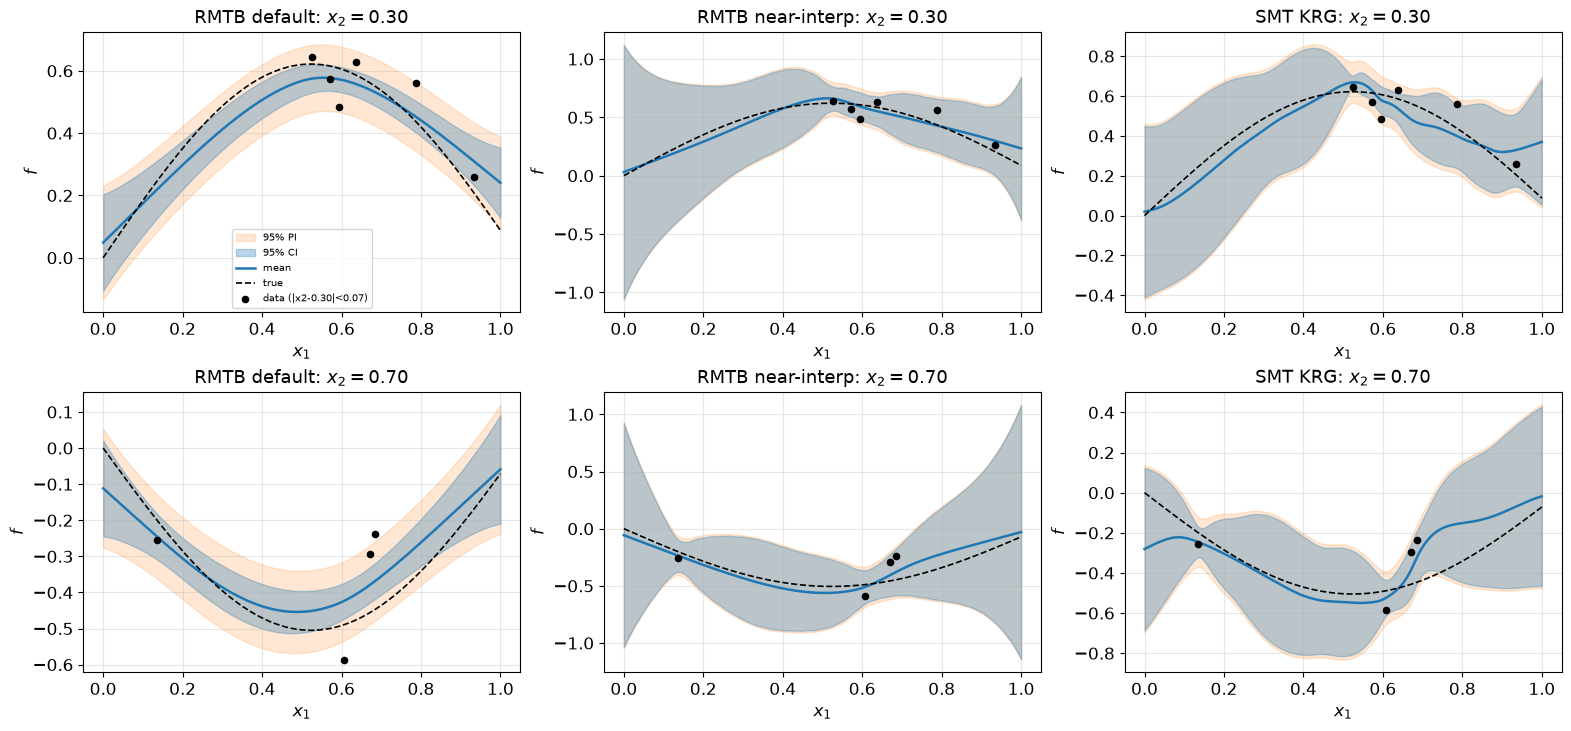

In [6]:
def plot_slices(models, labels, slice_axis_value_pairs, tol=0.07, n_fine=300):
    t = np.linspace(0, 1, n_fine)
    n_rows = len(slice_axis_value_pairs)
    n_cols = len(models)
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 3.6 * n_rows),
                             squeeze=False, constrained_layout=True)

    for i, x2_val in enumerate(slice_axis_value_pairs):
        line_pts = np.column_stack([t, np.full_like(t, x2_val)])
        true_vals = true_f(line_pts)
        near = np.abs(X[:, 1] - x2_val) < tol

        for j, (model, label) in enumerate(zip(models, labels)):
            ax = axs[i, j]
            R = model.predict(line_pts)
            ax.fill_between(t, R["pi_lower"], R["pi_upper"], color="tab:orange", alpha=0.18,
                            label="95% PI")
            ax.fill_between(t, R["ci_lower"], R["ci_upper"], color="tab:blue", alpha=0.30,
                            label="95% CI")
            ax.plot(t, R["mean"], color="tab:blue", lw=1.8, label="mean")
            ax.plot(t, true_vals, "k--", lw=1.2, label="true")
            if np.any(near):
                ax.scatter(X[near, 0], y[near], c="k", s=20, zorder=5,
                           label=f"data (|x2-{x2_val:.2f}|<{tol})")
            ax.set_title(f"{label}: $x_2={x2_val:.2f}$")
            ax.set_xlabel("$x_1$"); ax.set_ylabel("$f$")
            ax.grid(alpha=0.3)
            if i == 0 and j == 0:
                ax.legend(fontsize=7, loc="best")
    return fig


fig = plot_slices(models, labels, [0.3, 0.7])
plt.show()


**Same story, now visible in cross-section.** `RMTB default`'s bands (left
column) are broad and change gradually with `x_1` -- no narrowing right at
individual data points, only a slow overall tightening where the slice
passes nearer the main data cluster. `RMTB near-interp` (middle column) and
`SMT KRG` (right column) both show bands that visibly *pinch* right where a
training point sits close to the slice (e.g. the cluster of points near
`x_1~=0.5-0.65` in the `$x_2=0.3$` row) and widen again between them --
the 1-D cross-section of the same dimpling seen in the 2-D maps. The
near-interp mean also tracks the true function (dashed) and the nearby data
points noticeably more tightly than the default fit does, consistent with
its much lower training RMSE (`9.0e-3` vs. `4.7e-2`) -- at the cost of the
much wider bands away from data that make this mode unsuitable as a default
choice (Q20/Q21).


## Conclusion

- **Confirmed, with full 2-D maps and 1-D slices, not just a chat-level
  spot-check**: pushing RMTB toward near-interpolation (`energy_weight`
  small enough that `edf` approaches `n`, *not* a finer `num_ctrl_pts` --
  that lever does nothing, Q21's addendum) makes its own `Var_bayes`
  formula develop the same qualitative texture `SMT KRG` shows by default:
  individual dimples of reduced uncertainty at each training point, bands
  that visibly pinch near data and widen between/away from it, both in 2-D
  maps and in 1-D cross-sections.
- **Strictly qualitative, as scoped at the top of this notebook** -- no
  numerical agreement was sought or found (different color scales were used
  deliberately; the two models have unrelated priors and tuning procedures).
  What was being tested is texture, not numbers, and the texture matches.
- **This is not a free upgrade.** The near-interpolation configuration used
  here (`energy_weight=1e-4`, `edf=26.3` of `n=30`) sits well short of the
  genuinely risky settings Step 6 stress-tested (`energy_weight=1e-12` on
  real data, `cond(mtx)=6.9e10`) -- but it is still a deliberate move in
  exactly that direction, and the wide bands/less-tracked mean away from
  data in the 1-D slices are the visible cost of buying this Kriging-like
  local structure. `energy_weight~1e-2`, this project's standard choice, is
  not a worse model -- it is a different, deliberately smoother point on
  the same bias-locality tradeoff that also governs `KRG`'s own
  nugget/correlation-length tuning.
